# US-01: Análisis Exploratorio de Datos (EDA)
## Sistema Predictivo de Abandono de Clientes (Telco Customer Churn)

In [11]:
# Librerías que vamos a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)

print("Librerías cargadas")

Librerías cargadas


In [12]:
# Cargamos el dataset
df = pd.read_excel('Telco_customer_churn.xlsx')

print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()

El dataset tiene 7043 filas y 33 columnas


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [13]:
# Primero vemos qué tipo de datos tenemos y si hay nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [14]:
# Estadísticas básicas de las columnas numéricas
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [15]:
# Revisamos si hay valores nulos
nulos = df.isnull().sum()
print("Columnas con valores nulos:")
print(nulos[nulos > 0].sort_values(ascending=False))

print(f"\nTotal Charges tiene {df['Total Charges'].isnull().sum()} nulos")

Columnas con valores nulos:
Churn Reason    5174
dtype: int64

Total Charges tiene 0 nulos


Distribución de Churn:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje de clientes que se fueron: 26.5%


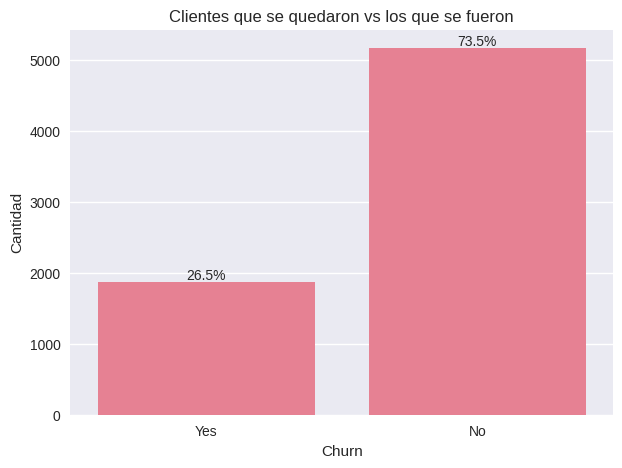

In [16]:
# Cómo está distribuido el churn
print("Distribución de Churn:")
print(df['Churn Label'].value_counts())
print(f"\nPorcentaje de clientes que se fueron: {df['Churn Label'].value_counts(normalize=True)['Yes']*100:.1f}%")

plt.figure(figsize=(7,5))
ax = sns.countplot(data=df, x='Churn Label')
plt.title('Clientes que se quedaron vs los que se fueron')
plt.xlabel('Churn')
plt.ylabel('Cantidad')

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')
plt.show()

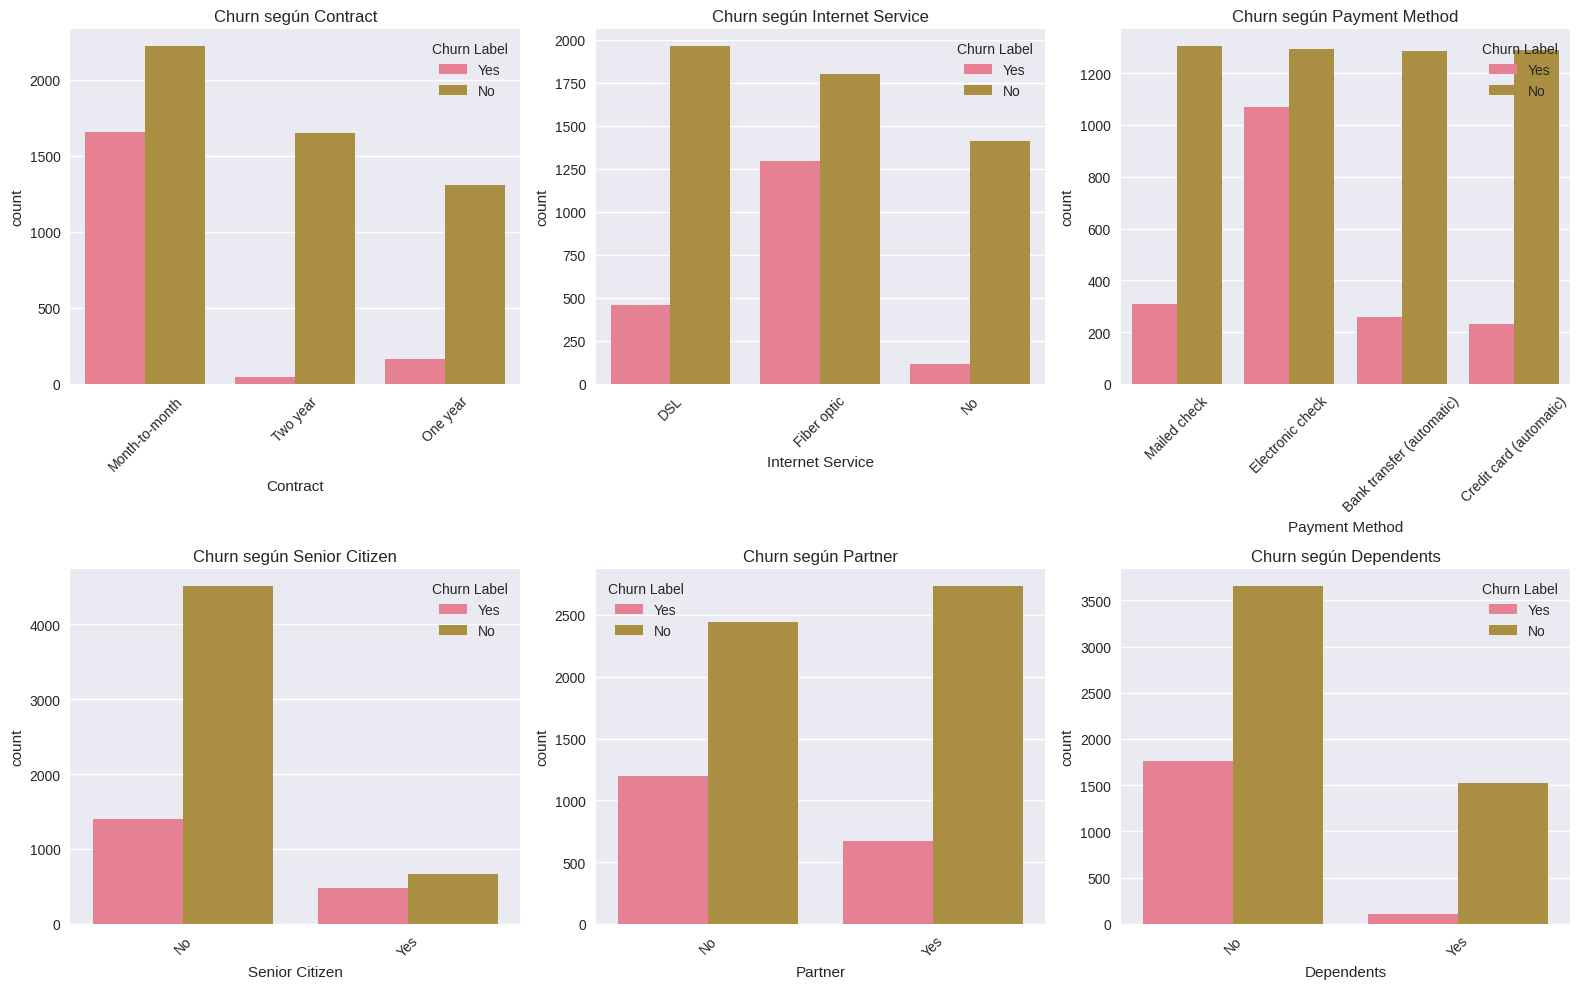

In [17]:
# Miramos algunas variables categóricas importantes
cat_cols = ['Contract', 'Internet Service', 'Payment Method', 'Senior Citizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Churn Label', ax=axes[i])
    axes[i].set_title(f'Churn según {col}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

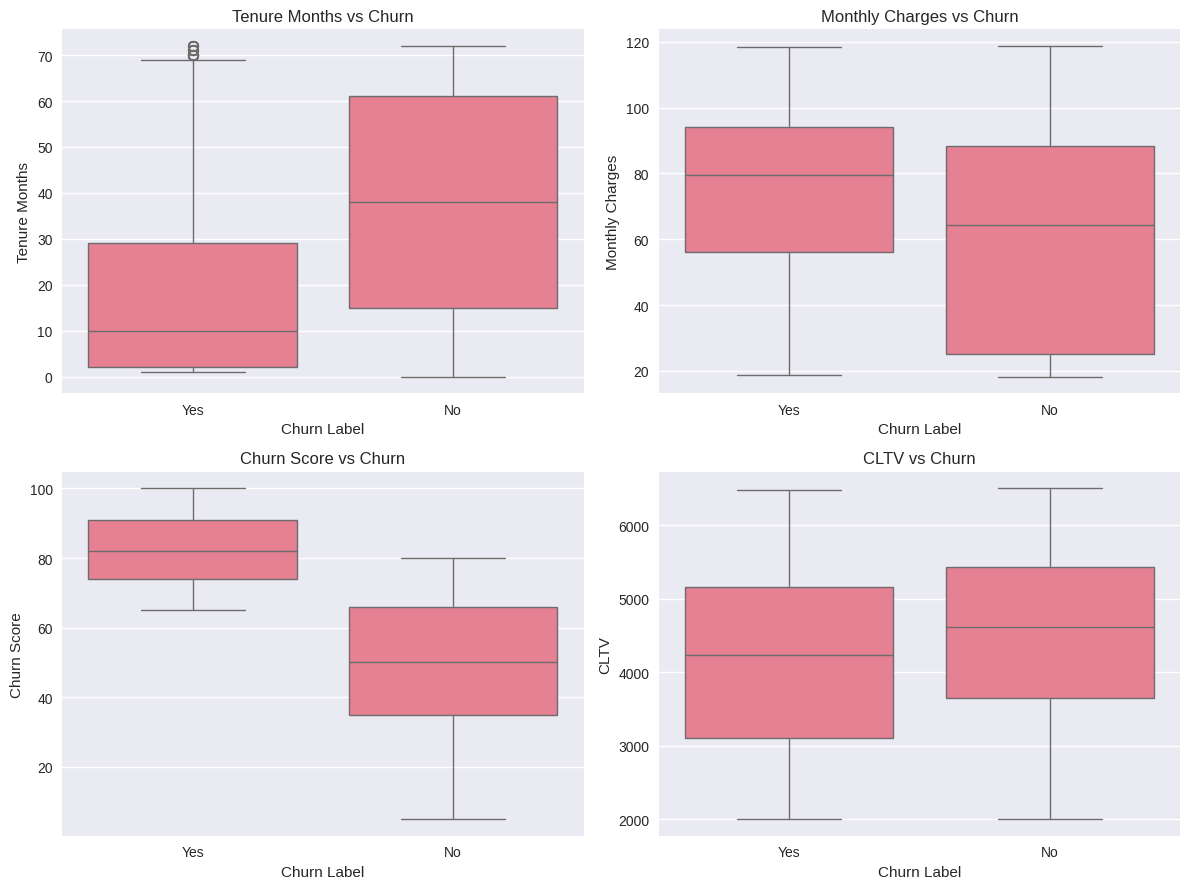

In [18]:
# Ahora variables numéricas
num_cols = ['Tenure Months', 'Monthly Charges', 'Churn Score', 'CLTV']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Churn Label', y=col, ax=axes[i])
    axes[i].set_title(f'{col} vs Churn')

plt.tight_layout()
plt.show()

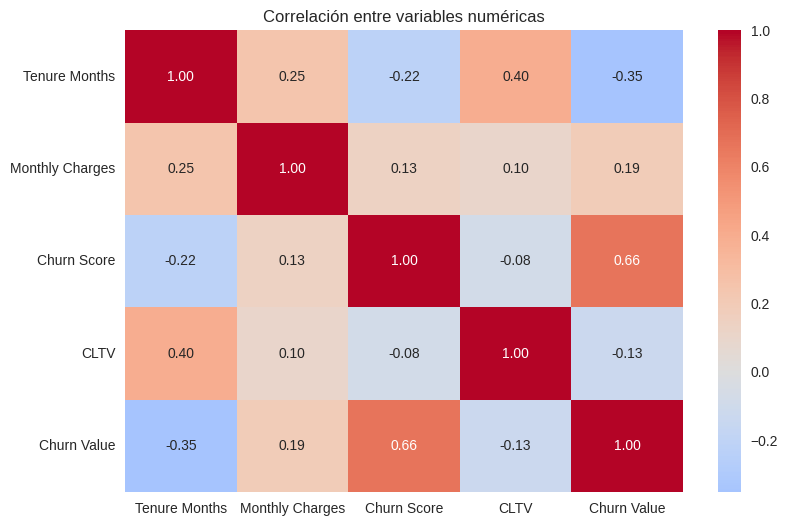

In [19]:
# Correlación entre variables numéricas
plt.figure(figsize=(9, 6))
corr_cols = ['Tenure Months', 'Monthly Charges', 'Churn Score', 'CLTV', 'Churn Value']
corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlación entre variables numéricas')
plt.show()

In [20]:
# Resumen de lo que encontramos
print("="*60)
print("Lo que vimos en el EDA")
print("="*60)

print(f"\n- El dataset tiene {df.shape[0]} clientes y {df.shape[1]} columnas.")
print(f"- La tasa de churn es del {df['Churn Label'].value_counts(normalize=True)['Yes']*100:.1f}%.")
print(f"- En Total Charges no aparecieron nulos (interesante, normalmente este dataset sí tiene algunos).")

print("\nCosas que se notan a simple vista:")
print("  • Los clientes con contrato Month-to-month se van mucho más.")
print("  • Fiber optic tiene más abandono que DSL.")
print("  • Los clientes nuevos (bajo Tenure) tienen más probabilidad de irse.")
print("  • Electronic check parece estar asociado a más churn.")

print("\nSiguiente paso: empezar a limpiar los datos (US-02).")

Lo que vimos en el EDA

- El dataset tiene 7043 clientes y 33 columnas.
- La tasa de churn es del 26.5%.
- En Total Charges no aparecieron nulos (interesante, normalmente este dataset sí tiene algunos).

Cosas que se notan a simple vista:
  • Los clientes con contrato Month-to-month se van mucho más.
  • Fiber optic tiene más abandono que DSL.
  • Los clientes nuevos (bajo Tenure) tienen más probabilidad de irse.
  • Electronic check parece estar asociado a más churn.

Siguiente paso: empezar a limpiar los datos (US-02).
